# Cryptocurrency Volatility Prediction
## Data Understanding

### Objective
This notebook performs the **data understanding and exploratory analysis** stage for a cryptocurrency volatility prediction project.

The dataset contains historical market data for **56 cryptocurrencies**, with observations spanning different date ranges. The main market variables are:

- `open`
- `high`
- `low`
- `close`
- `volume`
- `marketCap`

The analysis focuses on understanding the dataset, examining price behavior, calculating returns, and constructing rolling volatility measures that can later be used for machine-learning prediction.


## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

pd.set_option("display.max_columns", None)


## 2. Load the Dataset

> **Note:** Update `file_path` if your CSV is stored somewhere else.


In [2]:
# WHY:
# We first load the raw cryptocurrency dataset so that all later analysis is
# performed on the same source data.
#
# HOW:
# pandas.read_csv() reads the CSV file into a DataFrame.
#
# WHAT WE DERIVE:
# We obtain a structured table containing historical OHLCV/market-cap data
# for multiple cryptocurrencies.

file_path = r"C:/Users/Mayur/CRYPTOCURRECNY VOLATILITY PROJECT/data/raw/data.csv"
df = pd.read_csv(file_path)

df.head()


,Unnamed: 0,open,high,low,close,volume,marketCap,timestamp,crypto_name,date
0,0,112.900002,118.800003,107.142998,115.910004,0.0,1.288693e+09,2013-05-05T23:59:59.999Z,Bitcoin,2013-05-05
1,1,3.493130,3.692460,3.346060,3.590890,0.0,6.229819e+07,2013-05-05T23:59:59.999Z,Litecoin,2013-05-05
2,2,115.980003,124.663002,106.639999,112.300003,0.0,1.249023e+09,2013-05-06T23:59:59.999Z,Bitcoin,2013-05-06
3,3,3.594220,3.781020,3.116020,3.371250,0.0,5.859436e+07,2013-05-06T23:59:59.999Z,Litecoin,2013-05-06
4,4,112.250000,113.444000,97.699997,111.500000,0.0,1.240594e+09,2013-05-07T23:59:59.999Z,Bitcoin,2013-05-07


## 3. Basic Dataset Information

In [3]:
# WHY:
# Before analyzing the data, we need to know its size and the variables available.
#
# HOW:
# shape gives (number of rows, number of columns), while columns lists the
# variable names.
#
# WHAT WE DERIVE:
# The source dataset has 72,946 observations and the expected market/date fields.

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns)


Shape: (72946, 10)

Columns:
Index(['Unnamed: 0', 'open', 'high', 'low', 'close', 'volume', 'marketCap',
       'timestamp', 'crypto_name', 'date'],
      dtype='object')


In [4]:
# WHY:
# We need to understand the structure of every column and whether values are missing.
#
# HOW:
# info() shows row count, non-null count, data types, and memory usage.
#
# WHAT WE DERIVE:
# The main market columns are numeric, while timestamp/crypto_name/date are
# object/date-related fields. The source data contains 72,946 observations.

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72946 entries, 0 to 72945
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Unnamed: 0   72946 non-null  int64  
 1   open         72946 non-null  float64
 2   high         72946 non-null  float64
 3   low          72946 non-null  float64
 4   close        72946 non-null  float64
 5   volume       72946 non-null  float64
 6   marketCap    72946 non-null  float64
 7   timestamp    72946 non-null  object 
 8   crypto_name  72946 non-null  object 
 9   date         72946 non-null  object 
dtypes: float64(6), int64(1), object(3)
memory usage: 5.6+ MB


### Dataset observations

The source dataset contains **72,946 rows** and data for **56 cryptocurrencies**.

The market variables are numerical, while `timestamp`, `crypto_name`, and `date` are categorical/date-related fields.


In [5]:
# WHY:
# Volatility is being studied across multiple cryptocurrencies, so we need to
# know how many different assets are represented.
#
# HOW:
# nunique() counts distinct cryptocurrency names.
#
# WHAT WE DERIVE:
# The dataset contains 56 cryptocurrencies.

print("Number of cryptocurrencies:", df["crypto_name"].nunique())
print("\nCryptocurrencies:")
print(df["crypto_name"].unique())


Number of cryptocurrencies: 56

Cryptocurrencies:
['Bitcoin' 'Litecoin' 'XRP' 'Dogecoin' 'Monero' 'Stellar' 'Tether'
 'Ethereum' 'Ethereum Classic' 'Maker' 'Basic Attention Token' 'EOS'
 'Bitcoin Cash' 'BNB' 'TRON' 'Decentraland' 'Chainlink' 'Cardano'
 'Filecoin' 'Theta Network' 'Huobi Token' 'Ravencoin' 'Tezos' 'VeChain'
 'Quant' 'USD Coin' 'Cronos' 'Wrapped Bitcoin' 'Cosmos' 'Polygon' 'OKB'
 'UNUS SED LEO' 'Algorand' 'Chiliz' 'THORChain' 'Terra Classic'
 'FTX Token' 'Hedera' 'Binance USD' 'Dai' 'Solana' 'Avalanche' 'Shiba Inu'
 'The Sandbox' 'Polkadot' 'Elrond' 'Uniswap' 'Aave' 'NEAR Protocol' 'Flow'
 'Internet Computer' 'Casper' 'Toncoin' 'Chain' 'ApeCoin' 'Aptos']


## 4. Missing Values

In [6]:
# WHY:
# Missing values can break calculations and may introduce bias into a model.
#
# HOW:
# isnull().sum() counts missing values column by column.
#
# WHAT WE DERIVE:
# The original market/date columns have no missing values.

missing_values = df.isnull().sum()
print(missing_values)


Unnamed: 0     0
open           0
high           0
low            0
close          0
volume         0
marketCap      0
timestamp      0
crypto_name    0
date           0
dtype: int64


## 5. Duplicate Rows

In [7]:
# WHY:
# Duplicate observations can cause some market observations to be counted more
# than once and can distort statistics or model training.
#
# HOW:
# duplicated() identifies repeated rows and sum() counts them.
#
# WHAT WE DERIVE:
# We check that the dataset does not contain duplicated complete rows.

print("Number of duplicate rows:", df.duplicated().sum())


Number of duplicate rows: 0


## 6. Data Types

In [8]:
# WHY:
# Different types of data require different preprocessing.
#
# HOW:
# dtypes reports the data type of every column.
#
# WHAT WE DERIVE:
# OHLCV/marketCap are numerical variables; timestamp, crypto_name, and date
# require date/categorical handling.

print(df.dtypes)


Unnamed: 0       int64
open           float64
high           float64
low            float64
close          float64
volume         float64
marketCap      float64
timestamp       object
crypto_name     object
date            object
dtype: object


## 7. Numerical and Categorical Columns

In [9]:
# WHY:
# Statistical analysis and many ML algorithms require numerical variables.
#
# HOW:
# select_dtypes separates numerical and non-numerical columns.
#
# WHAT WE DERIVE:
# The numerical market variables are open, high, low, close, volume, and marketCap.

numerical_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical columns:")
print(numerical_columns)

print("\nCategorical/date columns:")
print(categorical_columns)


Numerical columns:
['Unnamed: 0', 'open', 'high', 'low', 'close', 'volume', 'marketCap']

Categorical/date columns:
['timestamp', 'crypto_name', 'date']


## 8. Descriptive Statistics

In [10]:
# WHY:
# Descriptive statistics give us a first understanding of the scale and spread
# of the market variables.
#
# HOW:
# describe() calculates count, mean, standard deviation, quartiles, minimum,
# and maximum.
#
# WHAT WE DERIVE:
# The variables have very different scales and large ranges, indicating that
# raw-price comparison across cryptocurrencies will not be appropriate.

df[numerical_columns].describe()


,Unnamed: 0,open,high,low,close,volume,marketCap
count,72946.000000,72946.000000,7.294600e+04,72946.000000,7.294600e+04,7.294600e+04,7.294600e+04
mean,36472.500000,870.194495,8.964124e+02,844.060640,8.712949e+02,2.207607e+09,1.474922e+10
std,21057.840705,5231.654470,5.398613e+03,5079.389387,5.235508e+03,9.617885e+09,7.501159e+10
min,0.000000,0.000000,1.022100e-10,0.000000,8.292000e-11,0.000000e+00,0.000000e+00
25%,18236.250000,0.167916,1.767999e-01,0.158630,1.682982e-01,8.320618e+06,1.860432e+08
50%,36472.500000,1.630666,1.717542e+00,1.541486,1.640219e+00,1.098756e+08,1.268539e+09
75%,54708.750000,26.070557,2.756868e+01,24.791776,2.625195e+01,6.691398e+08,5.118618e+09
max,72945.000000,67549.735581,1.621883e+05,66458.723733,6.756683e+04,3.509679e+11,1.274831e+12


## 9. Cryptocurrency Distribution

In [11]:
# WHY:
# Different cryptocurrencies have different numbers of observations.
#
# HOW:
# value_counts() counts observations for each crypto_name.
#
# WHAT WE DERIVE:
# The dataset is unbalanced across cryptocurrencies: some assets have thousands
# of observations while newer assets have much shorter histories.

crypto_counts = df["crypto_name"].value_counts()
crypto_counts


crypto_name
Bitcoin                  3248
Litecoin                 3248
XRP                      3157
Dogecoin                 3024
Monero                   2866
Stellar                  2791
Tether                   2582
Ethereum                 2424
Ethereum Classic         2072
Basic Attention Token    1760
EOS                      1730
Bitcoin Cash             1708
BNB                      1706
TRON                     1656
Decentraland             1652
Chainlink                1649
Cardano                  1638
Maker                    1605
Filecoin                 1565
Theta Network            1530
Huobi Token              1513
Ravencoin                1478
Tezos                    1365
VeChain                  1332
Quant                    1325
USD Coin                 1266
Cronos                   1199
Wrapped Bitcoin          1152
Cosmos                   1109
Polygon                  1064
OKB                      1062
UNUS SED LEO             1041
Algorand                 101

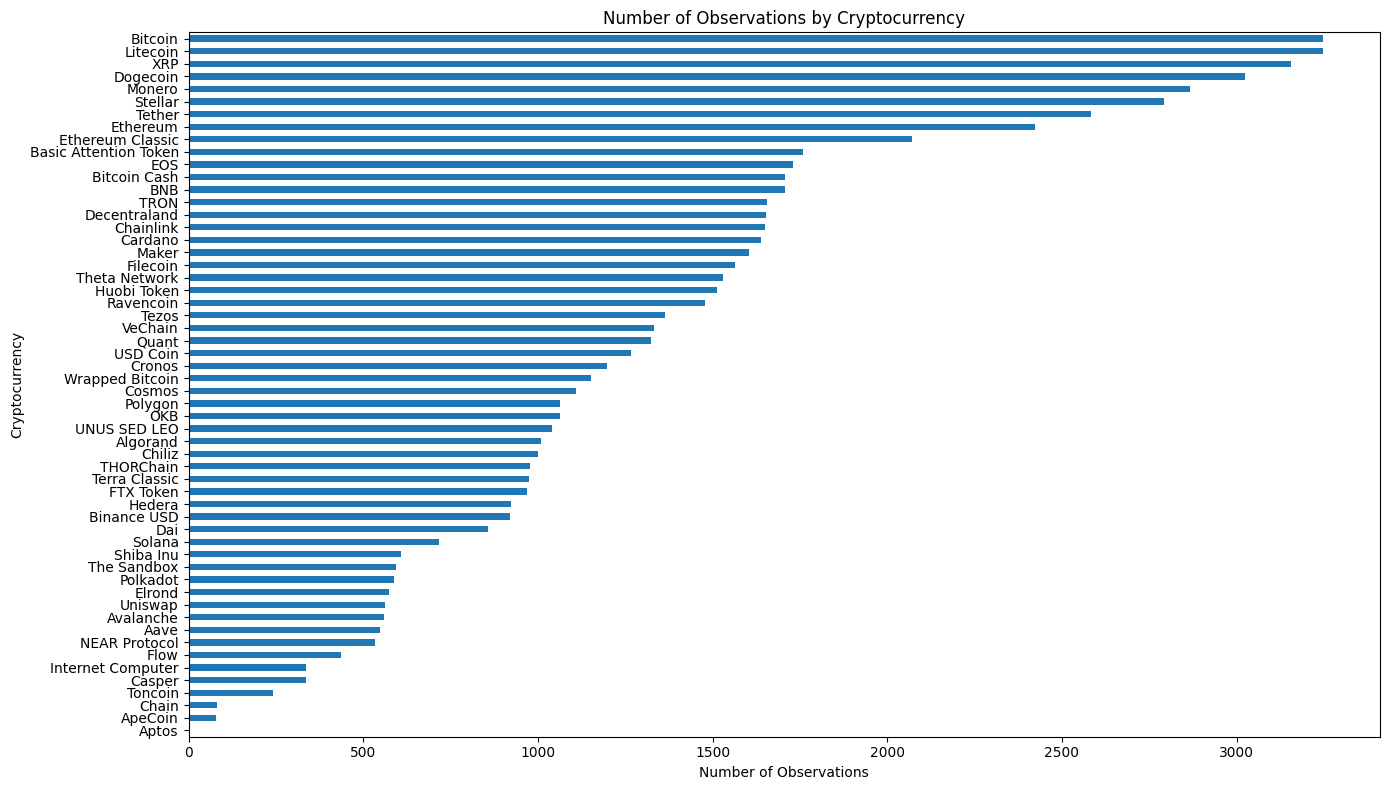

In [12]:
plt.figure(figsize=(14, 8))
crypto_counts.sort_values().plot(kind="barh")
plt.title("Number of Observations by Cryptocurrency")
plt.xlabel("Number of Observations")
plt.ylabel("Cryptocurrency")
plt.tight_layout()
plt.show()


## 10. Date Conversion

The `date` column is converted to pandas datetime format so that observations can be sorted chronologically and analyzed as a time series.


In [13]:
# WHY:
# Dates must be true datetime values for chronological sorting and time-series
# calculations.
#
# HOW:
# pd.to_datetime() converts the date strings into pandas timestamps.
#
# WHAT WE DERIVE:
# We can now reliably determine the time range and perform rolling calculations.

df["date"] = pd.to_datetime(df["date"])
df["timestamp"] = pd.to_datetime(df["timestamp"])

print("Minimum date:", df["date"].min())
print("Maximum date:", df["date"].max())


Minimum date: 2013-05-05 00:00:00
Maximum date: 2022-10-23 00:00:00


## 11. Historical Coverage by Cryptocurrency

In [14]:
# WHY:
# Each cryptocurrency entered the dataset at a different time.
#
# HOW:
# We group by crypto_name and calculate the first date, last date, and number
# of observations.
#
# WHAT WE DERIVE:
# Historical coverage differs substantially across cryptocurrencies. For example,
# some assets have long histories while very new assets have very few observations.

crypto_date_summary = (
    df.groupby("crypto_name")["date"]
      .agg(["min", "max", "count"])
      .sort_values("min")
)

crypto_date_summary


,min,max,count
crypto_name,,,
Litecoin,2013-05-05,2022-10-23,3248
Bitcoin,2013-05-05,2022-10-23,3248
XRP,2013-08-04,2022-10-23,3157
Dogecoin,2013-12-15,2022-10-23,3024
Monero,2014-05-21,2022-10-23,2866
Stellar,2014-08-05,2022-10-23,2791
Tether,2015-02-25,2022-10-23,2582
Ethereum,2015-08-07,2022-10-23,2424
Ethereum Classic,2016-07-24,2022-10-23,2072


## 12. Sort the Dataset Chronologically

For time-series calculations, observations must be ordered by cryptocurrency and date.


In [15]:
# WHY:
# Returns and rolling volatility depend on the previous observations of the
# same cryptocurrency.
#
# HOW:
# We sort first by cryptocurrency and then by date.
#
# WHAT WE DERIVE:
# Every cryptocurrency's observations are now in chronological order, making
# group-wise time-series calculations valid.

df = df.sort_values(["crypto_name", "date"]).copy()
df.reset_index(drop=True, inplace=True)

df[["crypto_name", "date", "close"]].head(10)


,crypto_name,date,close
0,Aave,2020-10-02,0.516571
1,Aave,2020-10-03,53.151488
2,Aave,2020-10-04,52.675035
3,Aave,2020-10-05,53.219243
4,Aave,2020-10-06,42.401599
5,Aave,2020-10-07,40.083976
6,Aave,2020-10-08,43.764463
7,Aave,2020-10-09,46.817744
8,Aave,2020-10-10,49.133718
9,Aave,2020-10-11,49.660726


## 13. Price Distribution

The dataset does **not** contain a `price` column. The `close` column is used as the cryptocurrency price for this analysis.


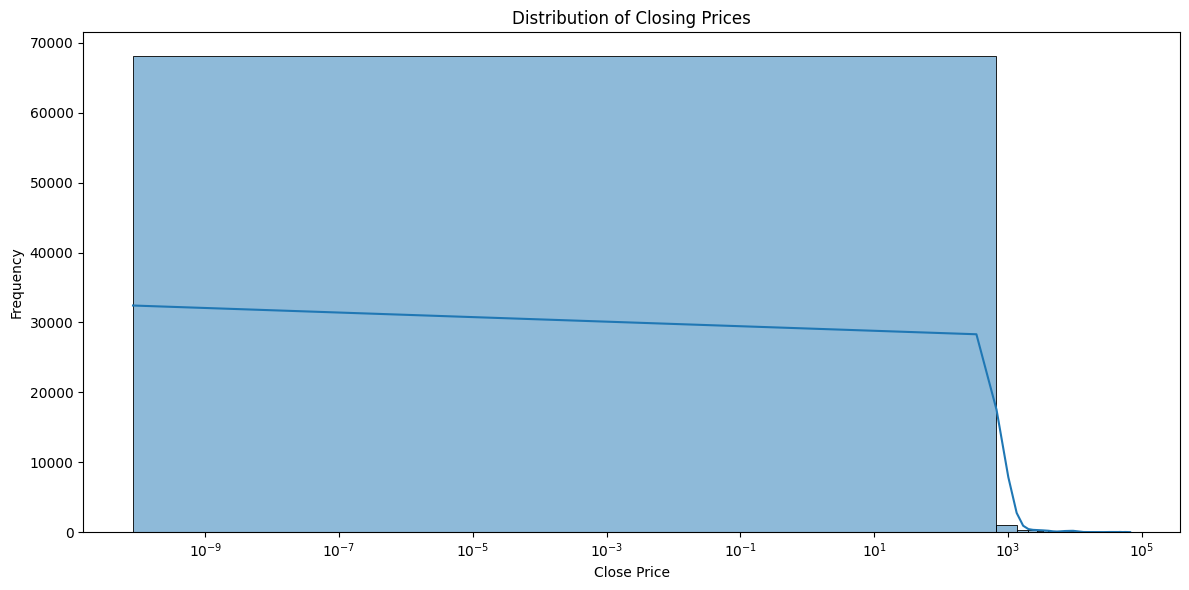

In [16]:
# WHY:
# We inspect the distribution of closing prices to understand their scale and
# whether extreme values are present.
#
# HOW:
# A histogram shows how frequently different closing-price values occur.
# A log x-axis is used because cryptocurrency prices span very different scales.
#
# WHAT WE DERIVE:
# Closing prices are highly uneven across assets, which motivates using normalized
# prices and percentage returns for cross-crypto comparisons.

plt.figure(figsize=(12, 6))
sns.histplot(df["close"], bins=100, kde=True)
plt.title("Distribution of Closing Prices")
plt.xlabel("Close Price")
plt.ylabel("Frequency")
plt.xscale("log")
plt.tight_layout()
plt.show()


## 14. Skewness of Numerical Variables

In [17]:
# WHY:
# Skewness tells us whether a variable is symmetrically distributed or has a
# long tail toward unusually large/small values.
#
# HOW:
# pandas skew() calculates the skewness for each numerical variable.
#
# WHAT WE DERIVE:
# Several market variables are strongly skewed, so raw means and ordinary-scale
# plots should be interpreted carefully.

skewness = df[numerical_columns].skew().sort_values(ascending=False)
skewness


marketCap     1.018329e+01
volume        9.499641e+00
high          8.648412e+00
low           8.468176e+00
open          8.456709e+00
close         8.449027e+00
Unnamed: 0    1.468165e-17
dtype: float64

## 15. Boxplots of Numerical Variables

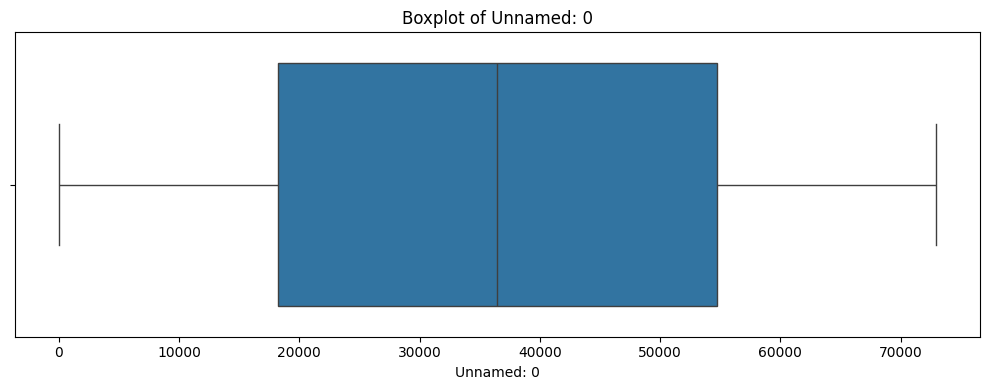

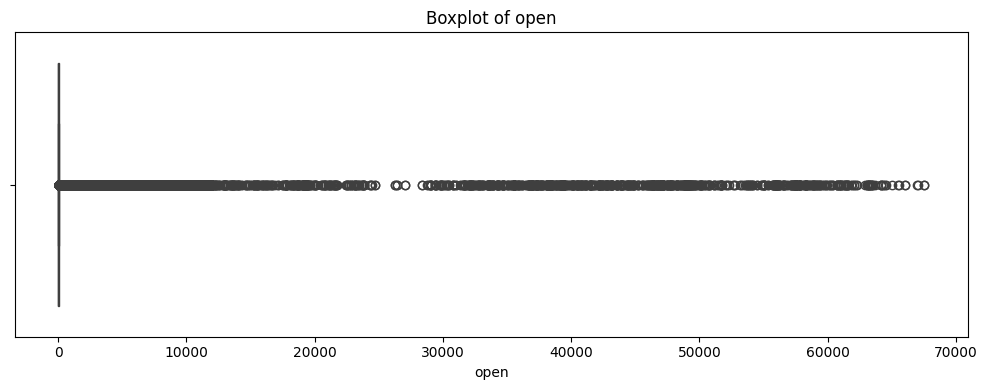

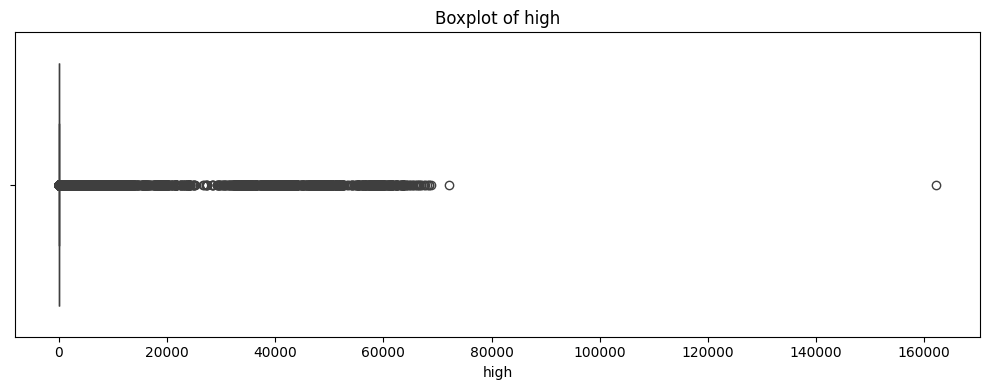

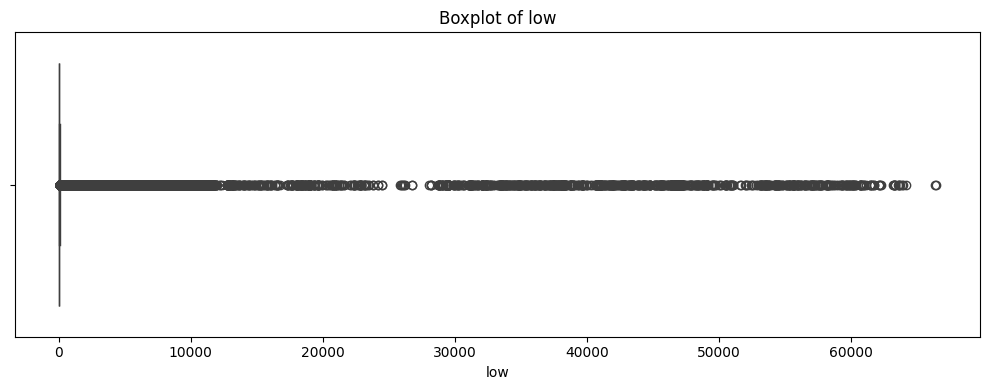

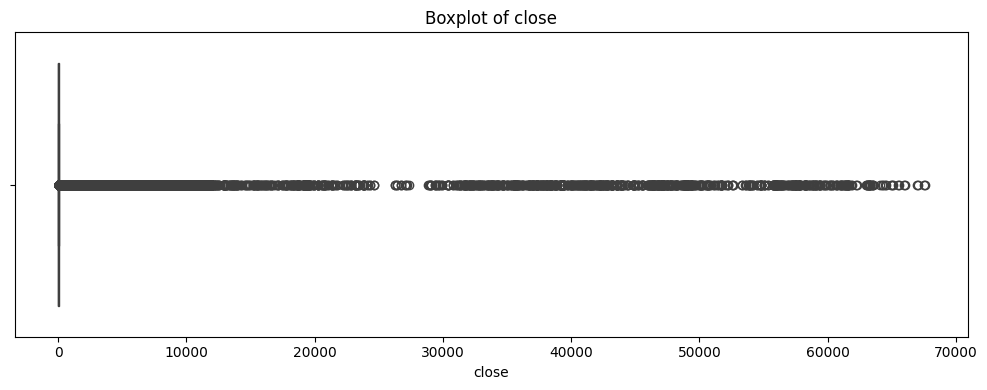

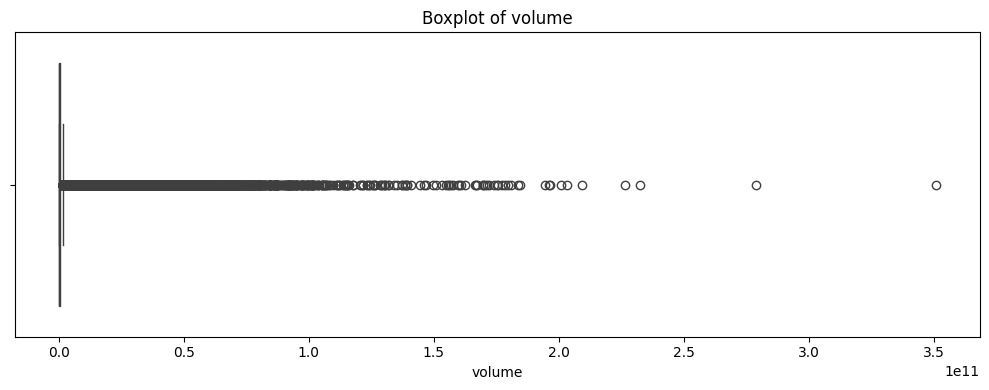

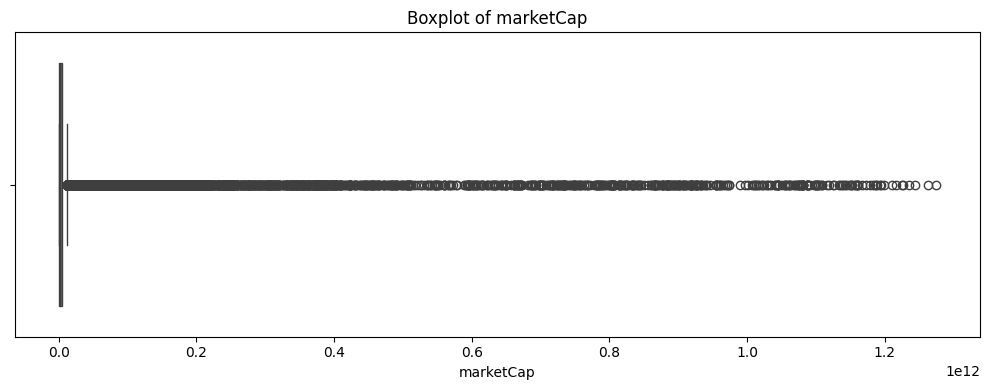

In [18]:
# WHY:
# Boxplots make outliers and the spread of each numerical variable easier to see.
#
# HOW:
# We create one boxplot per numerical column.
#
# WHAT WE DERIVE:
# The market variables contain substantial ranges and extreme observations,
# reinforcing the need for careful feature engineering and outlier investigation.

for column in numerical_columns:
    plt.figure(figsize=(10, 4))
    sns.boxplot(x=df[column])
    plt.title(f"Boxplot of {column}")
    plt.tight_layout()
    plt.show()


## 16. Normalized Closing Price

Cryptocurrencies have very different absolute price scales. Comparing raw closing prices on one graph can therefore be misleading.

To compare **relative price movement**, each cryptocurrency is normalized to a starting value of 100:

\[
Normalized\ Price = \frac{Close_t}{First\ Close} \times 100
\]


In [19]:
# WHY:
# Bitcoin, Ethereum, Shiba Inu, and other assets can have completely different
# absolute price levels. Comparing raw prices would therefore be misleading.
#
# HOW:
# For each cryptocurrency, we divide every closing price by that crypto's first
# observed closing price and multiply by 100.
#
# WHAT WE DERIVE:
# Every cryptocurrency starts at a common reference level of 100, allowing us
# to compare relative price growth rather than absolute dollar price.

df["normalized_close"] = (
    df["close"] /
    df.groupby("crypto_name")["close"].transform("first")
) * 100

df[["crypto_name", "date", "close", "normalized_close"]].head(10)


,crypto_name,date,close,normalized_close
0,Aave,2020-10-02,0.516571,100.000000
1,Aave,2020-10-03,53.151488,10289.280945
2,Aave,2020-10-04,52.675035,10197.047274
3,Aave,2020-10-05,53.219243,10302.397270
4,Aave,2020-10-06,42.401599,8208.273727
5,Aave,2020-10-07,40.083976,7759.618850
6,Aave,2020-10-08,43.764463,8472.102564
7,Aave,2020-10-09,46.817744,9063.169122
8,Aave,2020-10-10,49.133718,9511.504685
9,Aave,2020-10-11,49.660726,9613.525047


### Normalized price trends for selected cryptocurrencies

### Why this visualization?

A single plot of raw closing prices would be dominated by high-priced assets. The normalized plot puts every cryptocurrency on the same starting baseline of 100.

**What we derive:** we can compare relative growth and decline patterns across assets without confusing price level with performance.


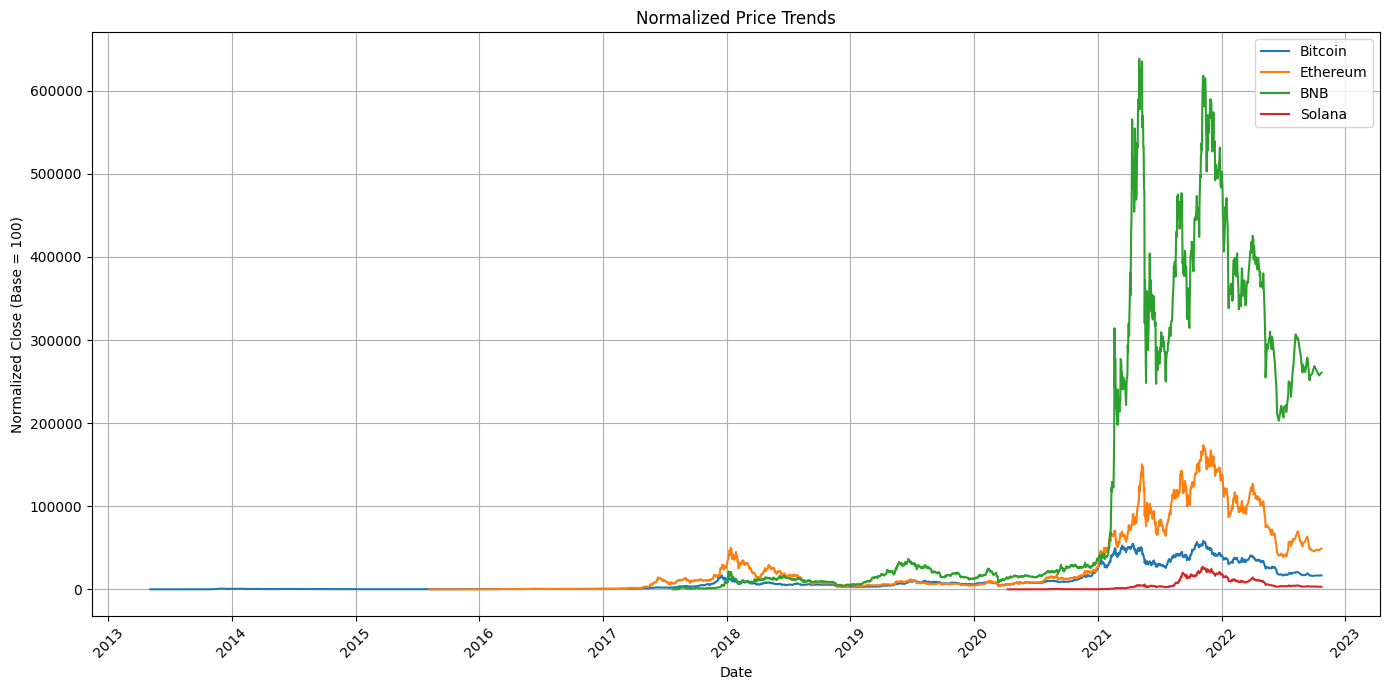

In [20]:
selected_coins = ["Bitcoin", "Ethereum", "BNB", "Solana"]

plt.figure(figsize=(14, 7))

for crypto in selected_coins:
    crypto_data = df[df["crypto_name"] == crypto]
    plt.plot(
        crypto_data["date"],
        crypto_data["normalized_close"],
        label=crypto
    )

plt.title("Normalized Price Trends")
plt.xlabel("Date")
plt.ylabel("Normalized Close (Base = 100)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 17. Normalized Price Trends for All Cryptocurrencies

Instead of putting all 56 cryptocurrencies on one graph, small multiples are used so that each cryptocurrency can be inspected separately.


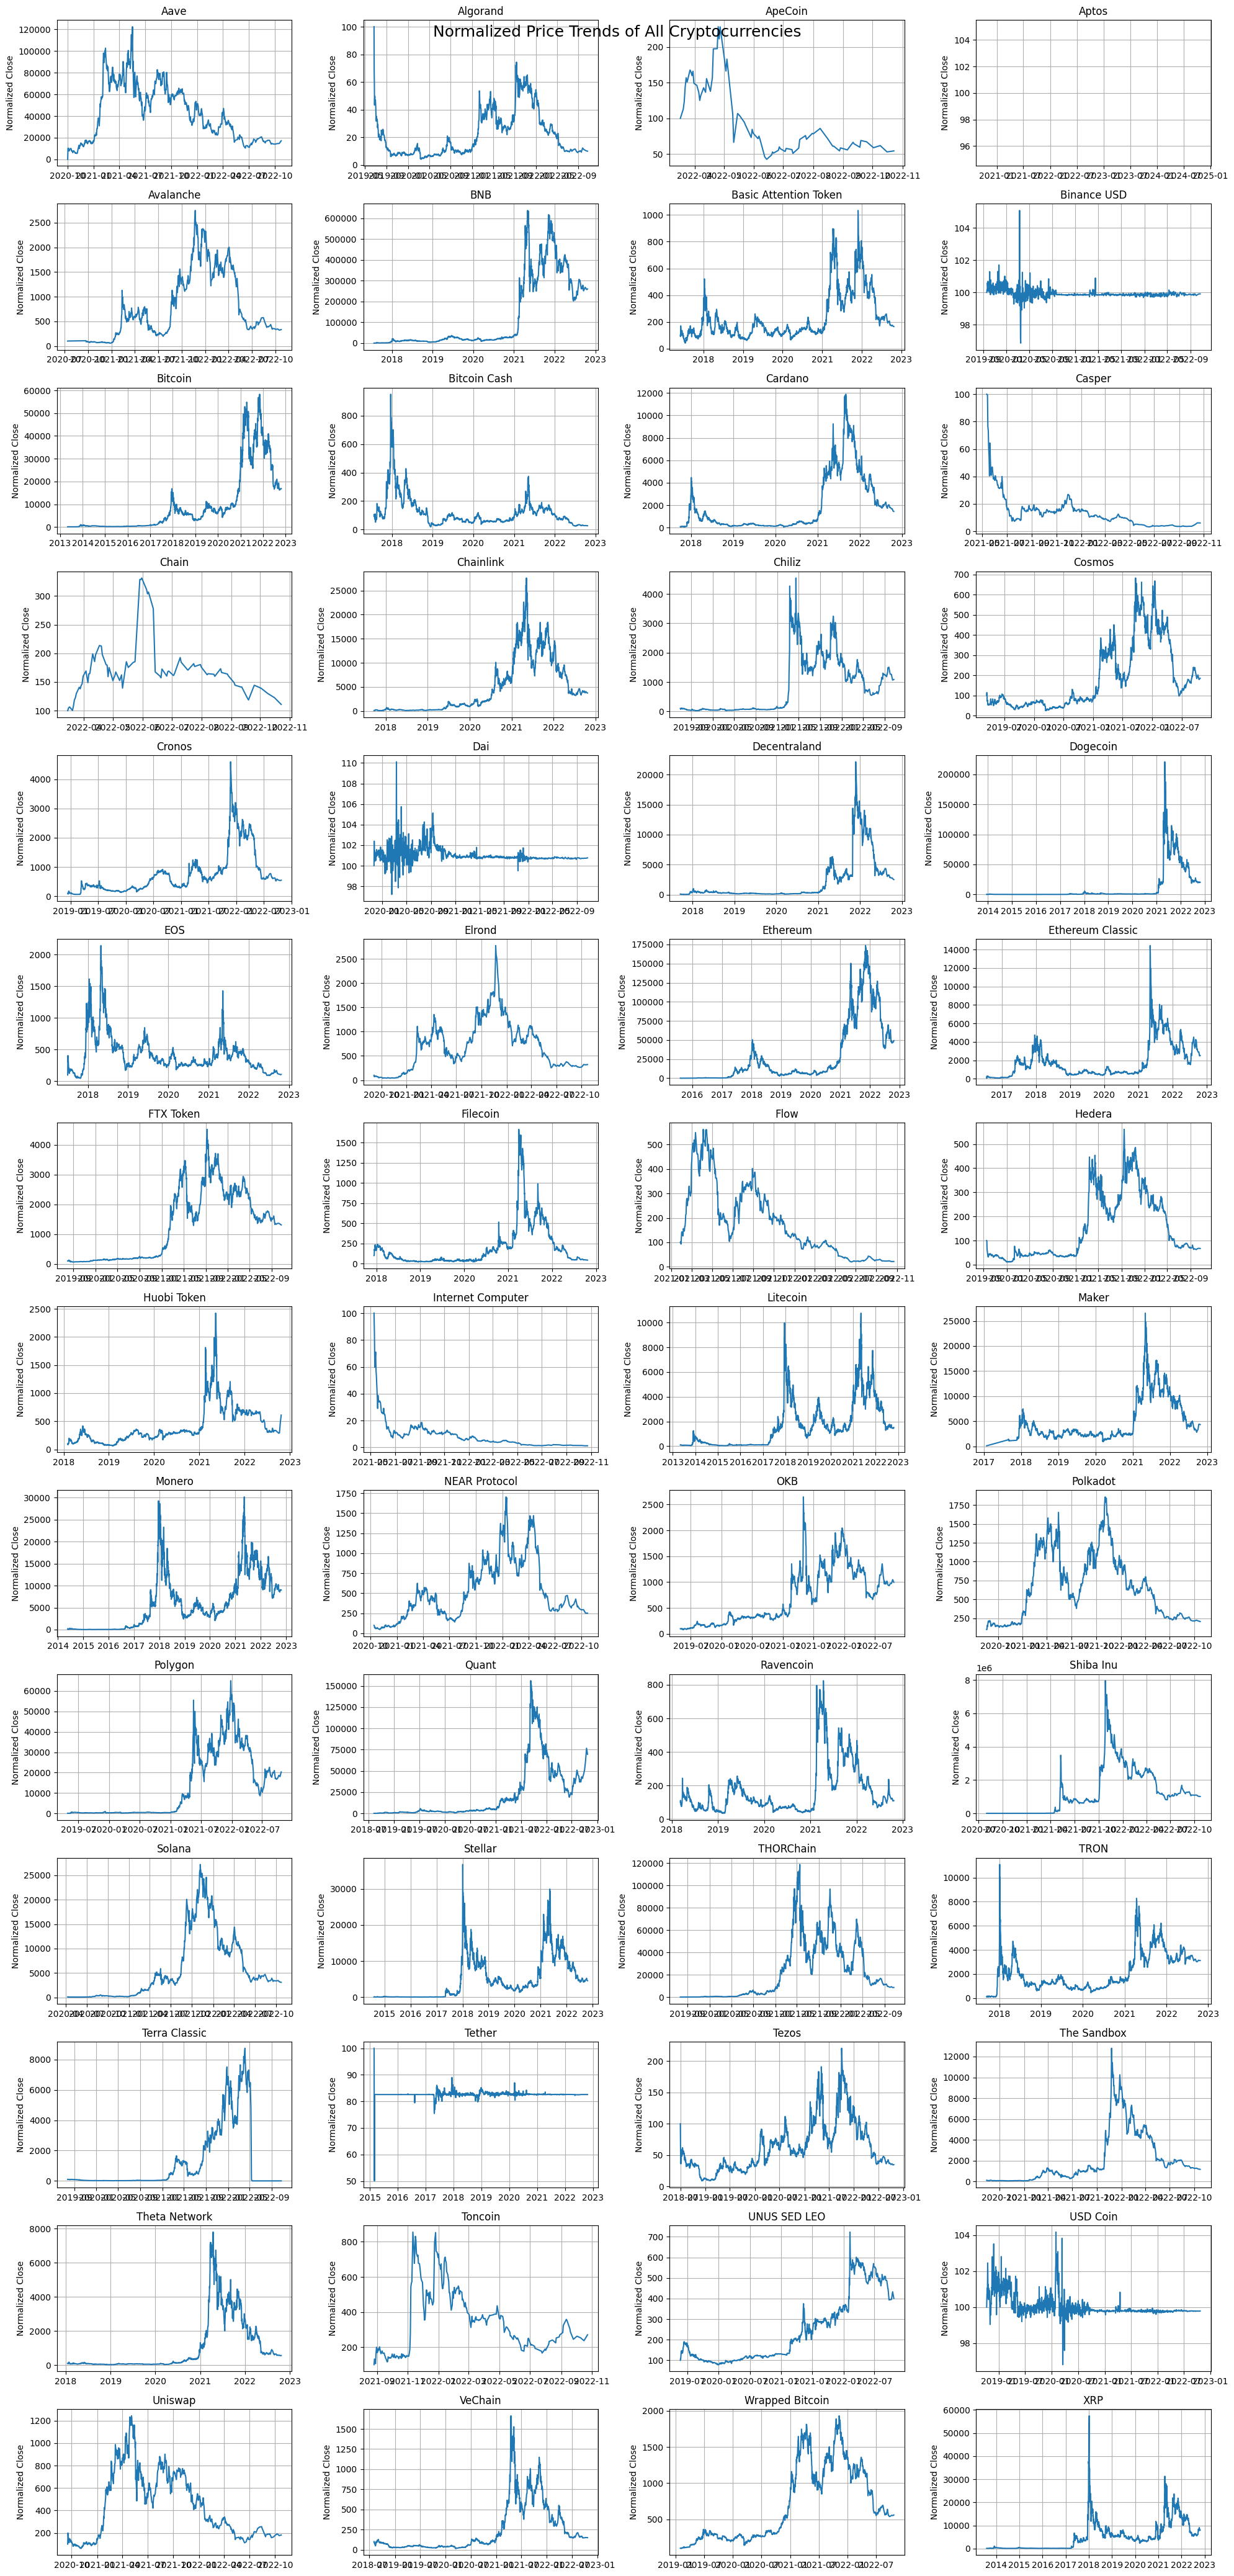

In [21]:
cryptos = df["crypto_name"].unique()

n_cols = 4
n_rows = math.ceil(len(cryptos) / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(20, n_rows * 3)
)

axes = axes.flatten()

for i, crypto in enumerate(cryptos):
    crypto_data = df[df["crypto_name"] == crypto]

    axes[i].plot(
        crypto_data["date"],
        crypto_data["normalized_close"]
    )

    axes[i].set_title(crypto)
    axes[i].set_ylabel("Normalized Close")
    axes[i].grid(True)

for i in range(len(cryptos), len(axes)):
    fig.delaxes(axes[i])

fig.suptitle(
    "Normalized Price Trends of All Cryptocurrencies",
    fontsize=18
)

plt.tight_layout()
plt.show()


## 18. Daily Returns

Absolute price changes are not directly comparable across cryptocurrencies because their prices differ greatly.

Daily percentage return is therefore calculated as:

\[
Return_t = \frac{Close_t - Close_{t-1}}{Close_{t-1}}
\]

The calculation is performed separately for each cryptocurrency.


In [22]:
# WHY:
# Volatility is based on how much returns fluctuate, not simply on the absolute
# price level. Percentage returns also make differently priced assets comparable.
#
# HOW:
# pct_change() calculates the percentage change in close from one observation
# to the next, separately for each cryptocurrency.
#
# WHAT WE DERIVE:
# We obtain a standardized measure of daily price movement called daily_return.

df["daily_return"] = (
    df.groupby("crypto_name")["close"]
      .pct_change()
)

df["daily_return"].describe()


count    72890.000000
mean         0.008279
std          0.763882
min         -0.999800
25%         -0.026011
50%          0.000000
75%          0.027196
max        177.327290
Name: daily_return, dtype: float64

### Daily Return Distribution

### Why this visualization?

Returns are the foundation for our volatility calculation. Looking at their distribution helps us see whether large positive/negative movements and heavy tails are present.

**What we derive:** cryptocurrency returns are not simply constant small changes; extreme movements exist and are important for the later volatility analysis.


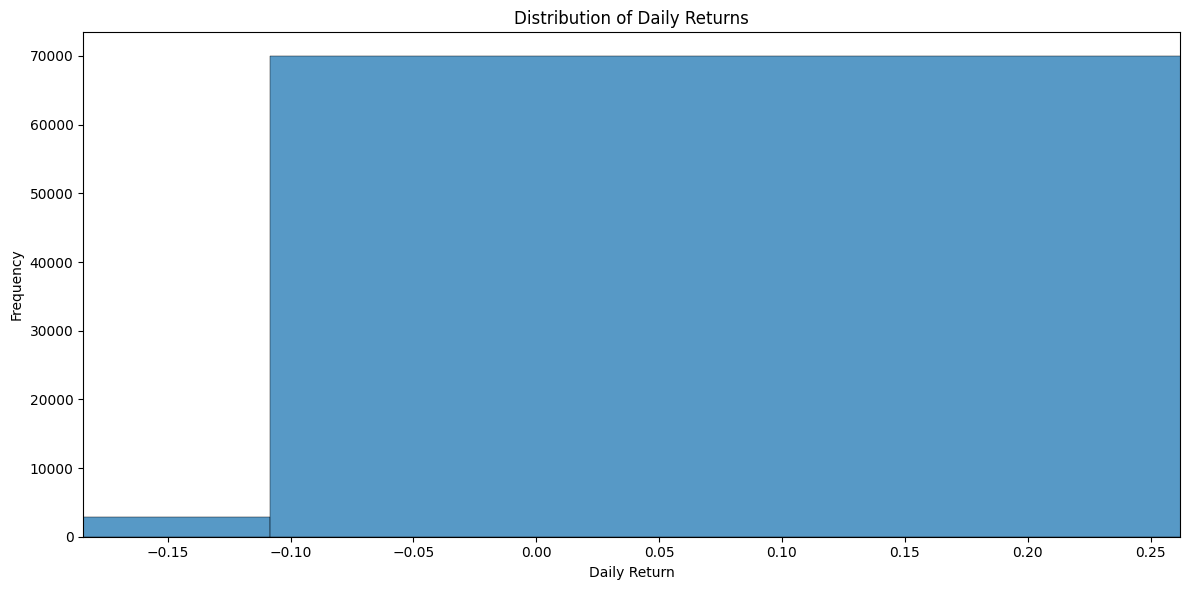

In [23]:
# WHY:
# We inspect the distribution of closing prices to understand their scale and
# whether extreme values are present.
#
# HOW:
# A histogram shows how frequently different closing-price values occur.
# A log x-axis is used because cryptocurrency prices span very different scales.
#
# WHAT WE DERIVE:
# Closing prices are highly uneven across assets, which motivates using normalized
# prices and percentage returns for cross-crypto comparisons.

plt.figure(figsize=(12, 6))
sns.histplot(
    df["daily_return"].dropna(),
    bins=200
)
plt.title("Distribution of Daily Returns")
plt.xlabel("Daily Return")
plt.ylabel("Frequency")
plt.xlim(
    df["daily_return"].quantile(0.01),
    df["daily_return"].quantile(0.99)
)
plt.tight_layout()
plt.show()


### Daily returns for all cryptocurrencies

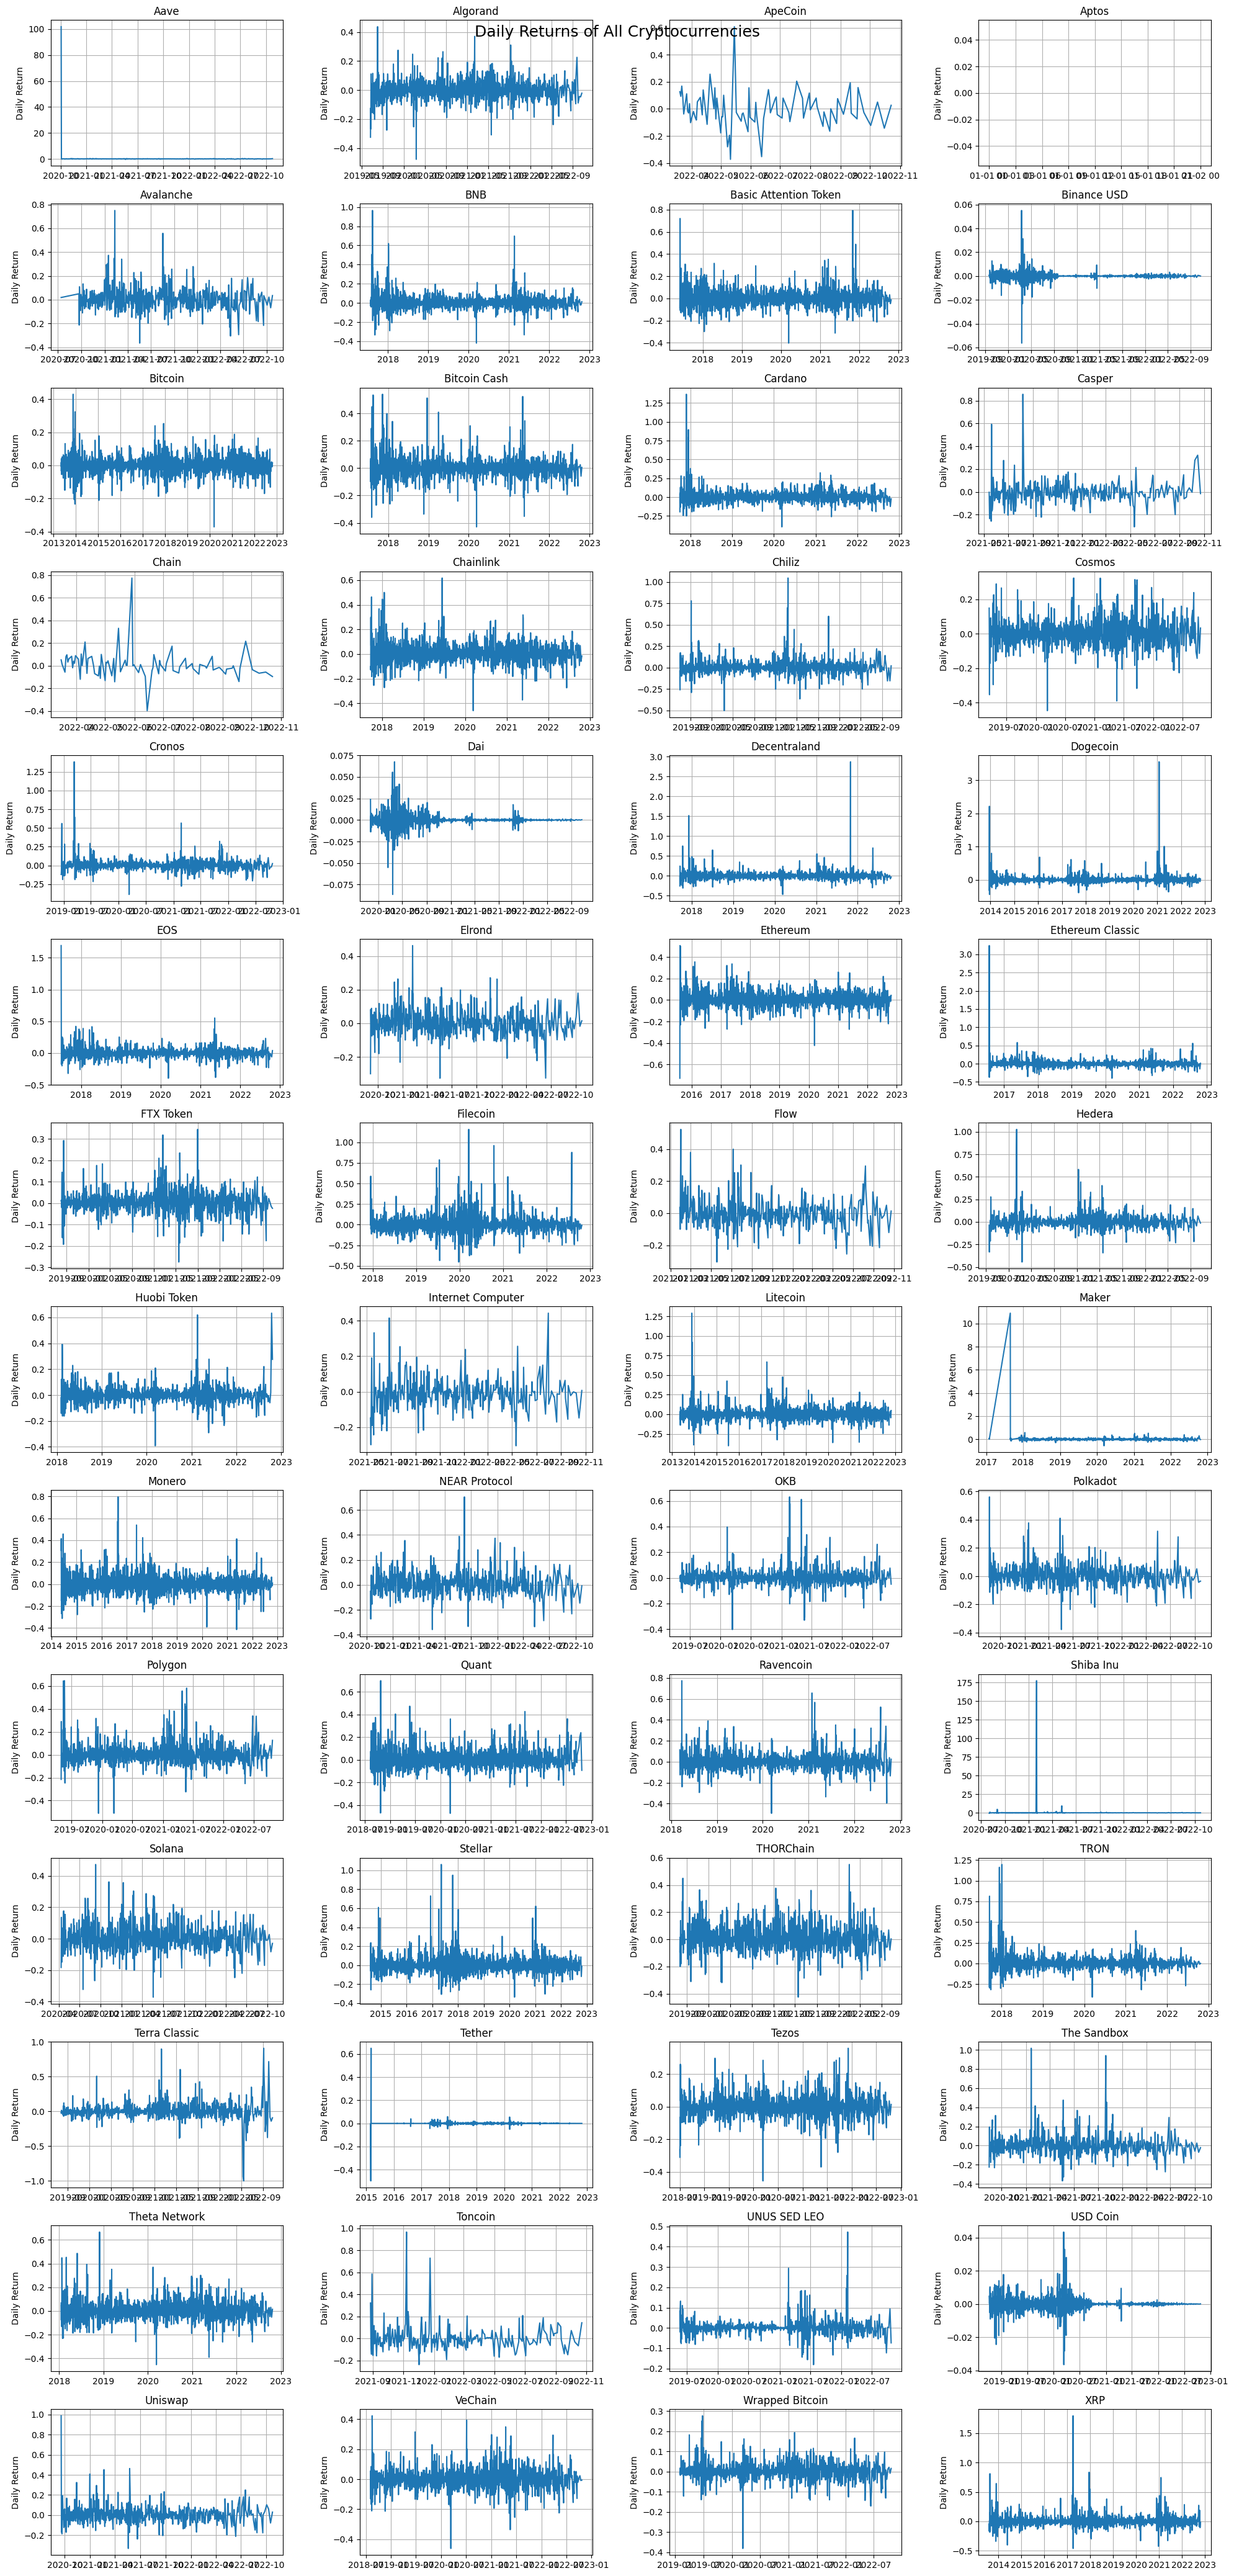

In [24]:
cryptos = df["crypto_name"].unique()

n_cols = 4
n_rows = math.ceil(len(cryptos) / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(20, n_rows * 3)
)

axes = axes.flatten()

for i, crypto in enumerate(cryptos):
    crypto_data = df[df["crypto_name"] == crypto]

    axes[i].plot(
        crypto_data["date"],
        crypto_data["daily_return"]
    )

    axes[i].set_title(crypto)
    axes[i].set_ylabel("Daily Return")
    axes[i].grid(True)

for i in range(len(cryptos), len(axes)):
    fig.delaxes(axes[i])

fig.suptitle(
    "Daily Returns of All Cryptocurrencies",
    fontsize=18
)

plt.tight_layout()
plt.show()


## 19. 7-Day Rolling Volatility

Volatility is measured using the standard deviation of daily returns over a rolling 7-day window.

\[
Volatility_{7d,t} =
Std(Return_{t-6}, ..., Return_t)
\]

A rolling window allows volatility to change over time instead of assigning one volatility value to the entire cryptocurrency history.


In [25]:
# WHY:
# A single overall volatility number would hide the fact that market risk changes
# over time. We therefore calculate a rolling measure.
#
# HOW:
# For each cryptocurrency, we calculate the standard deviation of daily returns
# over the previous 7 observations.
#
# WHAT WE DERIVE:
# volatility_7d represents short-term, time-varying market volatility.

df["volatility_7d"] = (
    df.groupby("crypto_name")["daily_return"]
      .transform(lambda x: x.rolling(window=7).std())
)

df["volatility_7d"].describe()


count    72560.000000
mean         0.065498
std          0.676696
min          0.000000
25%          0.028190
50%          0.047206
75%          0.073285
max         67.042805
Name: volatility_7d, dtype: float64

### 7-Day Rolling Volatility for Selected Cryptocurrencies

### Why this visualization?

This shows how short-term volatility changes through time rather than treating volatility as one fixed number.

**What we derive:** periods of higher and lower market uncertainty become visible, and different cryptocurrencies can experience volatility at different times.


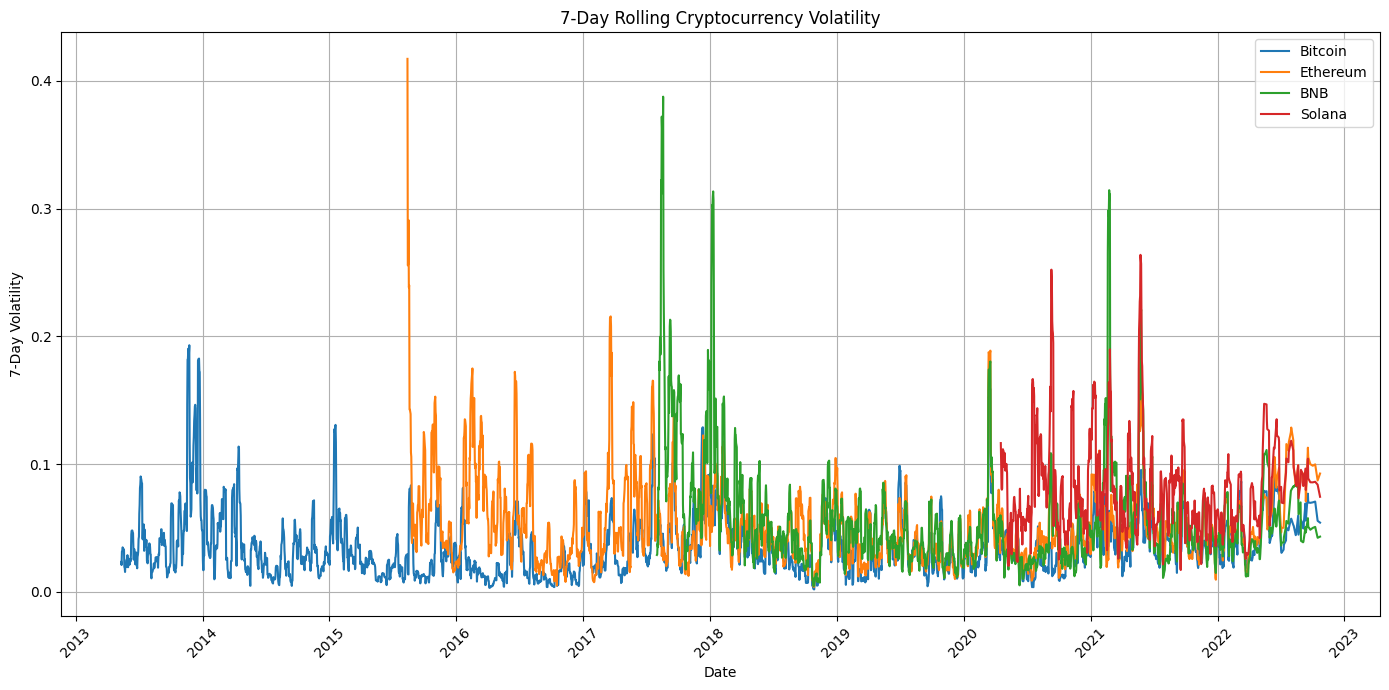

In [26]:
selected_coins = ["Bitcoin", "Ethereum", "BNB", "Solana"]

plt.figure(figsize=(14, 7))

for crypto in selected_coins:
    crypto_data = df[df["crypto_name"] == crypto]

    plt.plot(
        crypto_data["date"],
        crypto_data["volatility_7d"],
        label=crypto
    )

plt.title("7-Day Rolling Cryptocurrency Volatility")
plt.xlabel("Date")
plt.ylabel("7-Day Volatility")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


## 20. 30-Day Rolling Volatility

A longer rolling window is calculated to capture a smoother measure of volatility.

\[
Volatility_{30d,t} =
Std(Return_{t-29}, ..., Return_t)
\]


In [27]:
# WHY:
# A 7-day window reacts quickly to short-term market changes. We also want a
# smoother longer-term measure.
#
# HOW:
# We calculate the standard deviation of daily returns over a 30-observation
# rolling window for each cryptocurrency.
#
# WHAT WE DERIVE:
# volatility_30d provides a smoother view of volatility and can be compared
# with the short-term 7-day measure.

df["volatility_30d"] = (
    df.groupby("crypto_name")["daily_return"]
      .transform(lambda x: x.rolling(window=30).std())
)

df["volatility_30d"].describe()


count    71295.000000
mean         0.077234
std          0.669038
min          0.000000
25%          0.036824
50%          0.054632
75%          0.077999
max         32.377337
Name: volatility_30d, dtype: float64

### Compare 7-Day and 30-Day Volatility

### Why this visualization?

The 7-day measure reacts faster to recent changes, while the 30-day measure smooths short-term spikes.

**What we derive:** the two measures describe different volatility horizons. This helps us decide which horizon is appropriate for the prediction target and which can potentially be used as an explanatory feature.


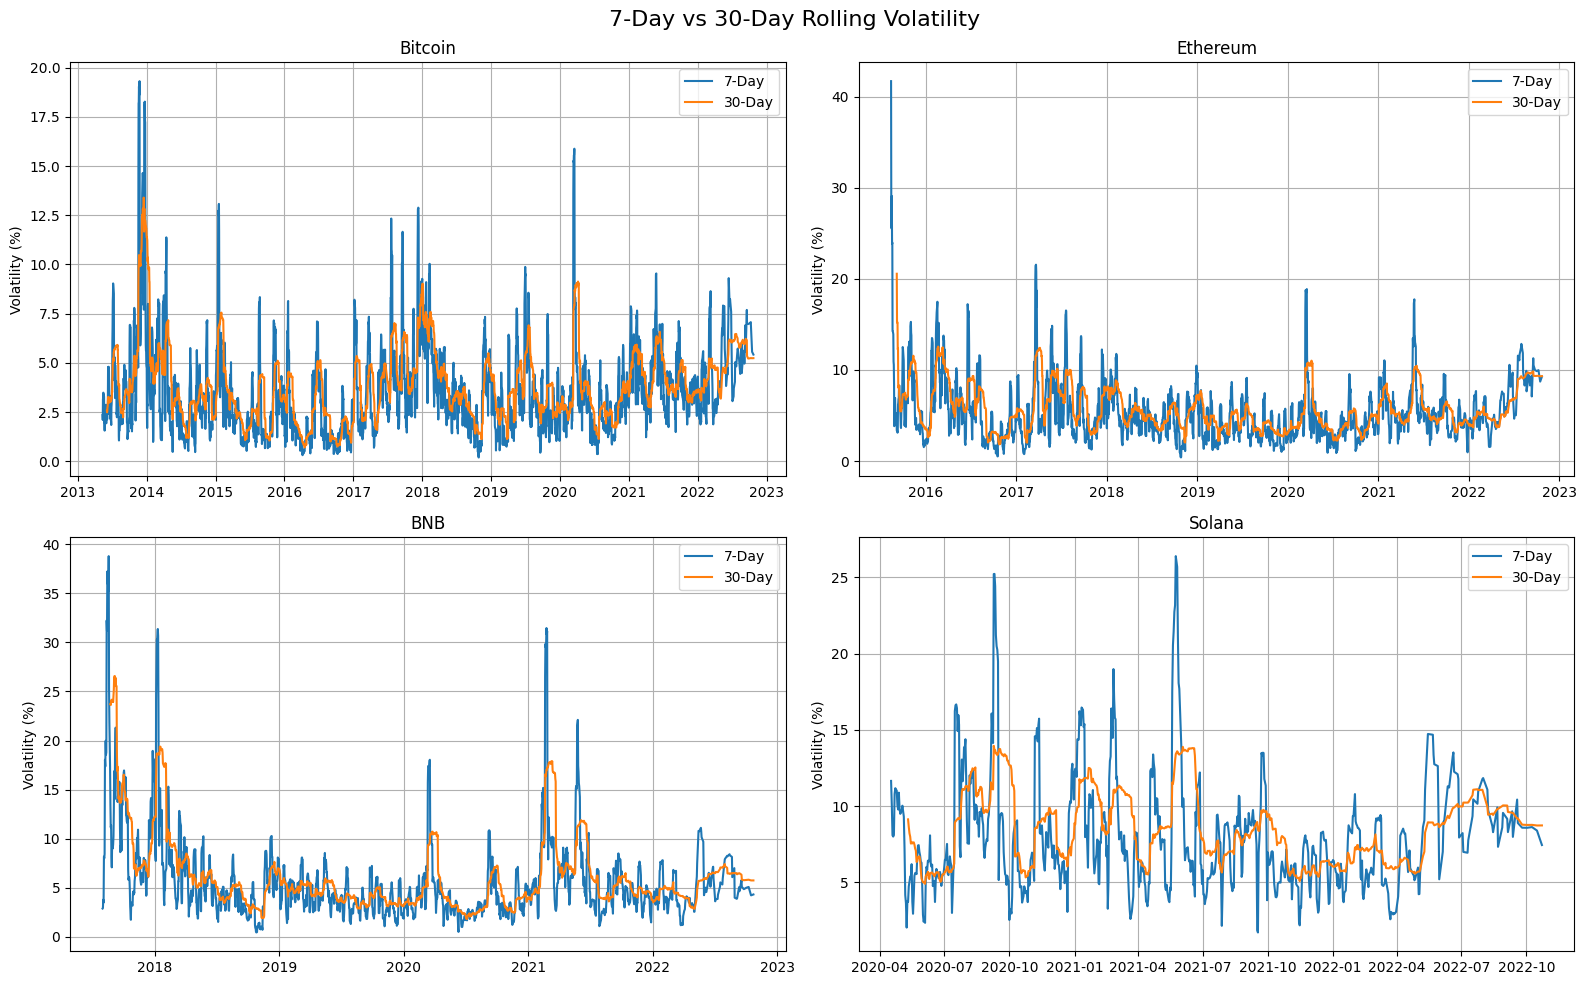

In [28]:
df["volatility_7d_pct"] = df["volatility_7d"] * 100
df["volatility_30d_pct"] = df["volatility_30d"] * 100

fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharex=False)
axes = axes.flatten()

for i, crypto in enumerate(selected_coins):
    crypto_data = df[df["crypto_name"] == crypto]

    axes[i].plot(
        crypto_data["date"],
        crypto_data["volatility_7d_pct"],
        label="7-Day"
    )

    axes[i].plot(
        crypto_data["date"],
        crypto_data["volatility_30d_pct"],
        label="30-Day"
    )

    axes[i].set_title(crypto)
    axes[i].set_ylabel("Volatility (%)")
    axes[i].grid(True)
    axes[i].legend()

plt.suptitle(
    "7-Day vs 30-Day Rolling Volatility",
    fontsize=16
)

plt.tight_layout()
plt.show()


## 21. Investigating Extreme Volatility

The volatility statistics contain extreme values. Rather than deleting them immediately, inspect the corresponding observations first.

The analysis identified particularly large values associated with very low-priced assets, including Shiba Inu in early 2021. Very small changes in a tiny price can create very large percentage returns.

Therefore, these observations should be investigated before any outlier treatment is applied.


In [29]:
# WHY:
# The volatility summary contains very large maximum values. Before removing
# anything, we need to understand where those values come from.
#
# HOW:
# nlargest() returns the observations with the highest 7-day volatility and
# shows the associated crypto, date, close, and daily return.
#
# WHAT WE DERIVE:
# The largest values are strongly associated with very low-priced assets such
# as Shiba Inu in early 2021. Tiny absolute price changes can create extremely
# large percentage returns, so these observations require investigation rather
# than automatic deletion.

df.nlargest(10, "volatility_7d")[
    [
        "date",
        "crypto_name",
        "close",
        "daily_return",
        "volatility_7d"
    ]
]


,date,crypto_name,close,daily_return,volatility_7d
50574,2021-02-01,Shiba Inu,1.000000e-08,-0.666667,67.042805
50579,2021-02-06,Shiba Inu,1.000000e-08,0.000000,67.036015
50577,2021-02-04,Shiba Inu,1.000000e-08,0.000000,67.032700
50578,2021-02-05,Shiba Inu,1.000000e-08,0.000000,67.019515
50576,2021-02-03,Shiba Inu,1.000000e-08,-0.500000,67.016194
50573,2021-01-31,Shiba Inu,3.000000e-08,177.327290,67.013455
50575,2021-02-02,Shiba Inu,2.000000e-08,1.000000,66.997537
7,2020-10-09,Aave,4.681774e+01,0.069766,38.517966
39882,2017-09-02,Maker,2.909840e+02,-0.059385,4.117885
39881,2017-09-01,Maker,3.093550e+02,0.034989,4.113701


## 22. Future Volatility Target

For machine learning, the model should predict **future** volatility rather than use future information to explain today's target.

The proposed target is the **next day's 7-day volatility**.

For each cryptocurrency:

\[
Target_t = Volatility_{7d,t+1}
\]

This is created with `shift(-1)` within each cryptocurrency.


In [30]:
# WHY:
# For machine learning, the model should predict future volatility using only
# information that was available at the current time. Using today's volatility
# as the target for today's features would not represent a future prediction.
#
# HOW:
# shift(-1) moves the next observation's 7-day volatility onto the current row,
# separately for each cryptocurrency.
#
# WHAT WE DERIVE:
# target_volatility represents the next available day's 7-day volatility, which
# can be used as the supervised-learning target once alignment and missing values
# are validated.

df["target_volatility"] = (
    df.groupby("crypto_name")["volatility_7d"]
      .shift(-1)
)

df[[
    "date",
    "crypto_name",
    "volatility_7d",
    "target_volatility"
]].head(15)


,date,crypto_name,volatility_7d,target_volatility
0,2020-10-02,Aave,NaN,NaN
1,2020-10-03,Aave,NaN,NaN
2,2020-10-04,Aave,NaN,NaN
3,2020-10-05,Aave,NaN,NaN
4,2020-10-06,Aave,NaN,NaN
5,2020-10-07,Aave,NaN,NaN
6,2020-10-08,Aave,NaN,38.517966
7,2020-10-09,Aave,38.517966,0.099951
8,2020-10-10,Aave,0.099951,0.100147
9,2020-10-11,Aave,0.100147,0.102326


### Validate target alignment

In [31]:
print("Target missing values:", df["target_volatility"].isna().sum())
print("\nLast observations:")
display(
    df[[
        "date",
        "crypto_name",
        "volatility_7d",
        "target_volatility"
    ]].tail(10)
)


Target missing values: 386

Last observations:


,date,crypto_name,volatility_7d,target_volatility
72936,2022-09-05,XRP,0.040246,0.051243
72937,2022-09-11,XRP,0.051243,0.039524
72938,2022-09-12,XRP,0.039524,0.039577
72939,2022-09-18,XRP,0.039577,0.034646
72940,2022-09-19,XRP,0.034646,0.099586
72941,2022-09-25,XRP,0.099586,0.112896
72942,2022-10-02,XRP,0.112896,0.121977
72943,2022-10-09,XRP,0.121977,0.140350
72944,2022-10-16,XRP,0.140350,0.142092
72945,2022-10-23,XRP,0.142092,NaN


## Overall Data Understanding Conclusion

### What we did and why

We moved from **raw market data → data validation → exploratory analysis → comparable price measures → returns → rolling volatility → a future prediction target**.

This sequence matters because a volatility prediction model should not be built directly on raw prices without first understanding their scale, time ordering, missingness, distributions, and temporal behavior.

### What we derived

1. The dataset contains 56 cryptocurrencies with unequal historical coverage.
2. `close` is the relevant price variable.
3. Raw prices are not directly comparable, so normalized prices were examined.
4. Daily percentage returns provide a comparable measure of price movement.
5. Rolling standard deviation of returns gives us a time-varying volatility measure.
6. Both 7-day and 30-day volatility were examined to represent different horizons.
7. Extreme volatility values were traced to particular observations instead of being blindly removed.
8. A future target was defined so the eventual ML model can learn a genuine forecasting task.

**The Data Understanding stage is therefore complete. The next stage is Feature Engineering and ML Preparation.**


## 23. Data Understanding Summary

### Main findings

- The dataset contains **72,946 observations** and **56 cryptocurrencies**.
- The main market variables are `open`, `high`, `low`, `close`, `volume`, and `marketCap`.
- `close` is used as the cryptocurrency price because there is no separate `price` column.
- Cryptocurrency histories have different lengths and start dates.
- Raw closing prices are not directly comparable across cryptocurrencies, so normalized prices were examined.
- Daily percentage returns provide a more comparable measure of price movement.
- 7-day and 30-day rolling standard deviations of returns provide time-varying volatility measures.
- The volatility distribution contains extreme observations, especially for very low-priced cryptocurrencies.
- These extreme observations should be investigated rather than automatically removed.
- A future target, `target_volatility`, has been created to represent the next day's 7-day volatility.

### Next stage

The next notebook stage is **feature engineering and machine-learning preparation**. At that stage we will:

1. Select predictor variables.
2. Create lagged features where appropriate.
3. Handle remaining missing values.
4. Prevent data leakage.
5. Perform a chronological train/test split.
6. Train and evaluate regression models.


In [32]:
df.to_csv("cleaned_crypto_data.csv", index=False)

In [34]:
from pathlib import Path

# Create the processed folder if it doesn't exist
processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

# Save the cleaned Bitcoin dataset
df.to_csv(processed_dir / "cleaned.csv", index=False)